# Linear component-wise boosting with `glmboost`

`glmboost` fits a linear model by component-wise boosting. At each iteration it
fits every candidate predictor to the pseudo-residual (the negative gradient of
the loss, which is the ordinary residual for squared error), selects the one
that fits best, and adds a shrunken multiple of that fit to its coefficient. The
stopped model therefore contains a subset of the candidate terms. This page is
for readers who want a sparse linear or generalized linear model, in particular
when there are many predictors. It covers variable selection, coefficient paths,
stopping by cross-validation and by AIC, a body-fat example and the R
equivalent.

```{figure} ../figures/mermaid-a148e917bcbf.svg
:name: mermaid-a148e917bcbf
:width: 250px
:align: center
:alt: Component-wise linear boosting selects one of many predictors at each iteration and accumulates small coefficient updates in a sparse model.

`glmboost` repeatedly recomputes residuals, selects one predictor, and adds a shrunken coefficient update, producing a sparse stopped model.
```


In [1]:
import numpy as np
import mboostrs as mb

rng = np.random.default_rng(1)
n, p = 200, 20
X = rng.normal(size=(n, p))
beta = np.zeros(p); beta[[0, 3, 7]] = [2.0, -1.5, 1.0]   # only 3 of 20 matter
y = X @ beta + rng.normal(scale=0.5, size=n)
data = {f"x{j}": X[:, j] for j in range(p)}
data["y"] = y

The formula lists the candidate terms; `glmboost` centers each predictor and
fits an intercept separately (matching R `mboost`).

In [2]:
formula = "y ~ " + " + ".join(f"x{j}" for j in range(p))
fit = mb.glmboost(formula, data=data, family=mb.Gaussian(),
                  control=mb.boost_control(mstop=300, nu=0.1))
print("candidate terms:", len(formula.split("+")),
      "| selected at least once:", len(set(fit.selected)))


candidate terms: 20 | selected at least once: 17


## Sparsity and variable selection
The data have 200 rows and 20 candidate predictors, of which only `x0`, `x3` and
`x7` enter the response. After 300 iterations the fit has selected 17 of the 20.

In [3]:
coefs = fit.coef()
nonzero = {k: round(v, 3) for k, v in coefs.items() if abs(v) > 1e-6}
nonzero

{'(Intercept)': -0.116,
 'x0': 2.067,
 'x1': 0.027,
 'x2': -0.006,
 'x3': -1.478,
 'x4': 0.019,
 'x5': -0.009,
 'x6': 0.011,
 'x7': 1.001,
 'x9': 0.02,
 'x10': -0.006,
 'x11': 0.008,
 'x13': -0.027,
 'x14': 0.018,
 'x15': 0.021,
 'x16': 0.03,
 'x18': 0.004,
 'x19': -0.038}

The three active predictors (`x0`, `x3`, `x7`) recover their true coefficients
— 2.0, -1.5, 1.0 — with estimates 2.067, -1.478 and 1.001. Every other term has an absolute coefficient of at most 0.038, which is at least 26 times smaller than the smallest signal (1.001). The
separation between the three signals and the remaining terms is what
component-wise selection provides: each iteration updates the term that reduces
the risk most, so the model grows one term at a time instead of fitting all $p$
terms at once.

**`coef()` returns only the learners that were selected.** An unselected term is
*absent from the mapping*, not present with a zero:

```python
coefs["x8"]   # KeyError: 'x8'
```

so `coefs.get("x8", 0.0)` returns zero when the term is absent.
The `abs(v) > 1e-6` filter above is only a display convention for the tiny
values; it does not remove coefficients from the fitted model.

**How many terms are selected depends on where you stop.** At `mstop=300`, well
past where this data stops improving, 17 of the 20 candidates have entered with
noise coefficients around 0.02. Stopping where cross-validation says to cuts
that to 8, and shrinks the largest noise coefficient by half:

| | selected of 20 | largest noise \|coef\| |
|---|---|---|
| `mstop = 300` | 17 | 0.038 |
| `mstop = 128` (cross-validated) | 8 | 0.016 |

At `mstop = 300` the three signals are 2.067 / -1.478 / 1.001, as printed above;
the counts and noise coefficient in the `mstop = 128` row are not printed by a
cell on this page. The
number of selected terms depends on `mstop`, so later sections choose the
stopping iteration by cross-validation and by AIC.

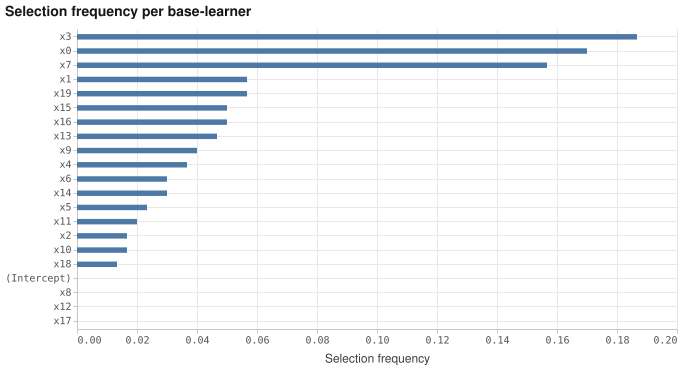

In [4]:
fit.plot_selected()

## Risk path

The in-bag risk drops fast, then flattens as `mstop` grows:

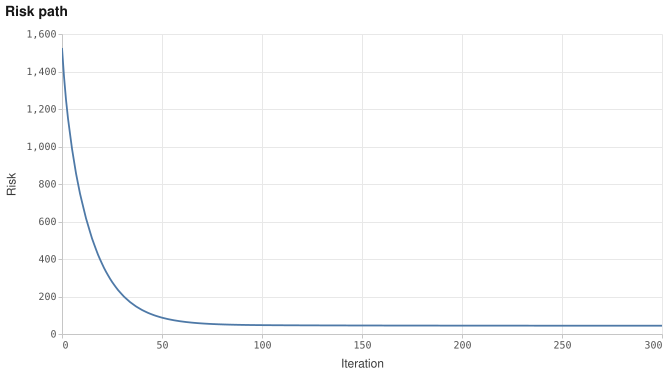

In [5]:
fit.plot_risk()

## Coefficient paths

`coef_path` returns each coefficient as a function of the boosting iteration —
the boosting equivalent of a regularization path. The built-in
`plot_coef_path` visualizes this automatically:

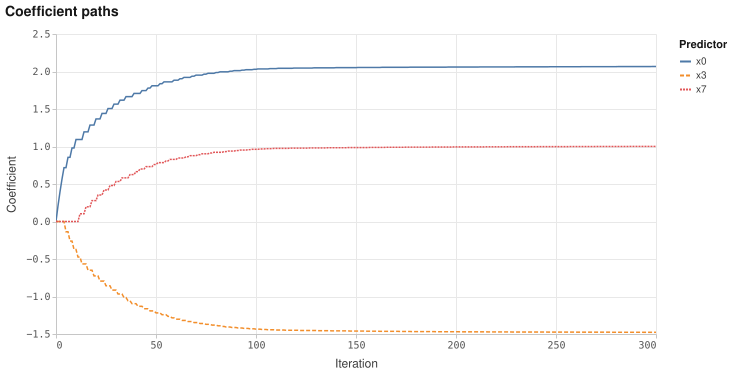

In [6]:
fit.plot_coef_path(which=["x0", "x3", "x7"])

You can also access the raw path data and draw it manually:

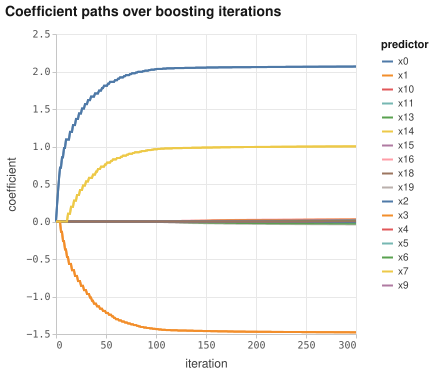

In [7]:
path = fit.coef_path()        # dict: name -> array of length mstop+1
import polars as pl
import altair as alt
rows = []
for name, vals in path.items():
    if name == "(Intercept)":
        continue
    for i, v in enumerate(vals):
        rows.append({"iteration": i, "coefficient": v, "predictor": name})
pdf = pl.DataFrame(rows)
highlight = ["x0", "x3", "x7"]
base = alt.Chart(pdf).mark_line().encode(x="iteration", y="coefficient", color="predictor")
hl = alt.Chart(pdf.filter(pl.col("predictor").is_in(highlight))).mark_line(strokeWidth=2).encode(x="iteration", y="coefficient", color="predictor")
(base + hl).properties(
    title="Coefficient paths over boosting iterations"
)

:::{tip}
Each line traces one predictor's coefficient from zero to its final value.
A predictor that enters early (steep slope) has strong partial correlation
with the response (its unique linear contribution after accounting for other
predictors). A predictor that enters late or barely moves contributes
little — consider dropping it in a simpler model.
:::

`fit.plot()` is a shortcut for `fit.plot_coef_path()`. See
[](plotting_serialization.ipynb) for all plot functions.

## Tuning and prediction

### Cross-validated risk

`cvrisk` estimates out-of-sample risk as a function of iteration: fit the model
on B resampled subsets (folds), evaluate the loss on the held-out points at
every m, average across folds, then pick the iteration with the minimum
average risk. Three resampling schemes are available — bootstrap, kfold,
subsampling — chosen with `type=` (see [](model_selection.ipynb) for a
comparison and [](../methodology/model_selection) for the theory).

In [8]:
cvr = fit.cvrisk(type="kfold", B=10, seed=0)
m_opt = cvr.optimal_mstop
yhat = fit.predict(mstop=m_opt)
print("m_opt:", m_opt, " train RMSE:", round(float(np.sqrt(np.mean((yhat - y) ** 2))), 3))

m_opt: 128  train RMSE: 0.479


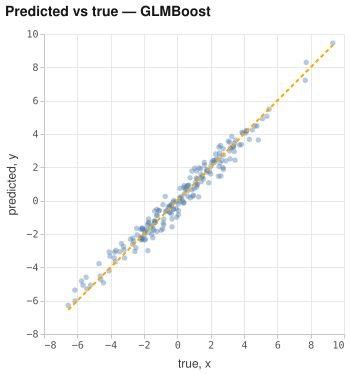

In [9]:
import polars as pl
import altair as alt
alt.Chart(pl.DataFrame({"true": y, "predicted": yhat})).mark_circle(opacity=0.4).encode(
    x="true", y="predicted"
).properties(title="Predicted vs true — GLMBoost") + alt.Chart(
    pl.DataFrame({"x": [y.min(), y.max()], "y": [y.min(), y.max()]})
).mark_line(color="orange", strokeDash=[4, 3]).encode(x="x", y="y")

If `m_opt` is close to 0, the model is mostly intercept; if it's near the
maximum, you may need more iterations. Here `m_opt = 128` is the iteration at which the cross-validated risk is smallest;
the fitted path has 300 iterations.

### AIC-based stopping

AIC penalizes the training log-likelihood by the model's effective degrees of
freedom. The textbook form is $-2\ell(m) + 2\,\text{df}(m)$, with
$\text{df}(m) = \operatorname{tr}(2 B_m - B_m B_m^\top)$ and $B_m$ the
boosting hat matrix. The iteration that minimizes it balances fit and
complexity without resampling.

`fit.aic()` does not return that expression. It returns `mboost`'s
**normalized corrected** criterion, which is the criterion `mboost` reports and the one compared with R:

$$\text{AIC}_c(m) = \log\!\left(\frac{\text{risk}(m)}{\sum_i w_i}\right)
+ \frac{1 + \text{df}(m)/\sum_i w_i}{1 - (\text{df}(m)+2)/\sum_i w_i}.$$

The printed values are around 1 because the risk is divided by total weight
and put on a log scale, giving a per-observation criterion. Applying the textbook expression to the `logLik` in the same
table will not reproduce it. See [](../methodology/model_selection) for the
derivation and the gMDL variant.

In [10]:
aic = fit.aic()
print("AIC-optimal mstop:", aic.mstop)

AIC-optimal mstop: 140


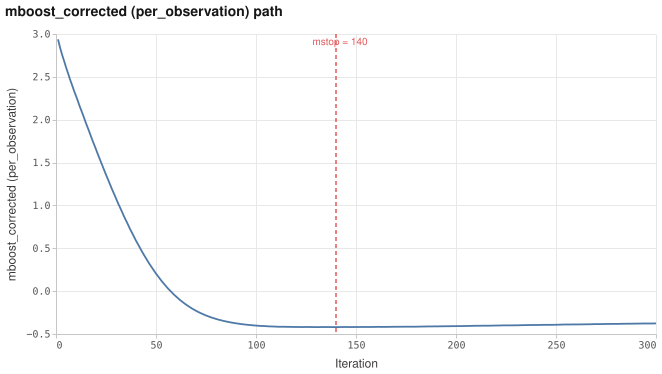

In [11]:
mb.plot.plot_aic(aic)

## Example: body-fat data

The `bodyfat` dataset (71 women, DEXA-measured body fat plus anthropometric
measurements) is the running example in the `mboost` hands-on tutorial
{cite}`hofner2014mboost_tutorial`. It is small enough to fit instantly and has a widely reproduced result: a
handful of circumference measurements dominate.


In [12]:
bodyfat = mb.datasets.bodyfat()
bf_data = {c: bodyfat[c].to_numpy() for c in bodyfat.columns}
bf_predictors = [c for c in bodyfat.columns if c != "DEXfat"]
bf_formula = "DEXfat ~ " + " + ".join(bf_predictors)

bf_fit = mb.glmboost(bf_formula, data=bf_data, family=mb.Gaussian(),
                      control=mb.boost_control(mstop=100, nu=0.1))
bf_coefs = {k: round(v, 3) for k, v in bf_fit.coef().items() if abs(v) > 1e-6}
bf_coefs


{'(Intercept)': -98.817,
 'age': 0.014,
 'waistcirc': 0.19,
 'hipcirc': 0.352,
 'elbowbreadth': -0.384,
 'kneebreadth': 1.737,
 'anthro3a': 3.327,
 'anthro3b': 3.657,
 'anthro3c': 0.595}

At `mstop=100` (the tutorial's default), `hipcirc`, `kneebreadth`, and the two
anthropometric summary scores (`anthro3a`, `anthro3b`) carry the largest
coefficients — waist and hip circumference plus knee breadth are the
classic predictors of body fat percentage in this dataset. This reproduces
the tutorial's `glmboost(DEXfat ~ ., data = bodyfat)` call; the R parity test
`tests/test_r_examples/test_cvrisk_bodyfat.py` checks this exact fit
(coefficients, offset, and `cvrisk` output) against R `mboost` within the
project's parity tolerance of about 1e-6 relative.


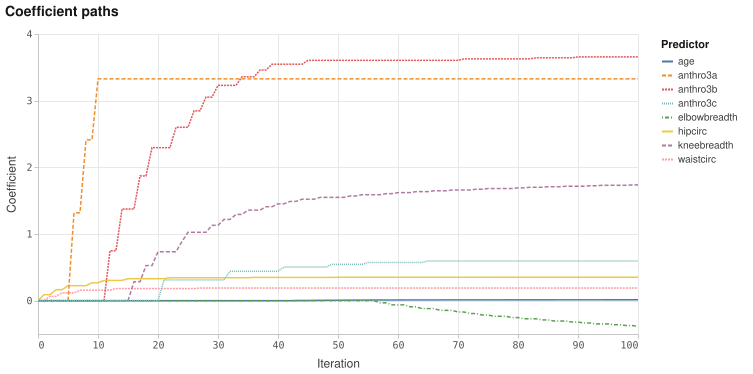

In [13]:
bf_fit.plot_coef_path()


The `AicResult` object provides `.aic` (full trace), `.mstop` (optimal
iteration), and `.df` (hat-trace at each step). AIC is available for all
GLMBoost models because linear (`bols`) base-learners always have a hat matrix.

:::{note}
AIC is **not** available after unpickling a model (the Rust learner state is
not serialized). In that case, `fit.aic()` returns `None` — use `cvrisk()`
instead.
:::

---

## The same workflow in R

The R binding supports `glmboost`, `cvrisk`, `coef`, `predict`, and `fitted`:

```r
library(mboostrs)
set.seed(1)
n <- 200; p <- 20
X <- matrix(rnorm(n * p), n, p)
beta <- rep(0, p); beta[c(1, 4, 8)] <- c(2.0, -1.5, 1.0)
y <- X %*% beta + rnorm(n, sd = 0.5)
data <- as.data.frame(cbind(X, y))

formula_str <- paste("y ~", paste0("V", 1:p, collapse = " + "))
fit <- glmboost(as.formula(formula_str), data = data, family = Gaussian(),
                control = boost_control(mstop = 300, nu = 0.1))

# Coefficients — only non-zero
coefs <- coef(fit)
print(round(coefs[abs(coefs) > 1e-6], 3))

# Cross-validated mstop
folds <- cv_weights(n, type = "kfold", B = 10, seed = 0)
cvr <- cvrisk(fit, folds = folds)
m_opt <- mstop(cvr)
yhat <- predict(fit, newdata = data, mstop = m_opt)
cat("m_opt:", m_opt, "  train RMSE:", sqrt(mean((yhat - y)^2)), "\n")
```

:::{note}
R's `glmboost` accepts bare column names (auto-converted to linear base
learners) as well as explicit `bols()` terms. The Python API follows the same
convention: `"y ~ x0 + x1"` in the formula is equivalent to
`"y ~ bols(x0) + bols(x1)"`. The expansion of a bare
column name depends on the fitting function: `bols` under `glmboost`, `bbs`
under `gamboost`.
:::

Available in R: `aic()`, `hatvalues()`, `confint()`, `summary()`, `logLik()`, `residuals()`,
`varimp()`, `update()`, `coef_path()`, `plot_coef_path()`, `plot_risk()`, `plot_varimp()`, `plot_selected()`,
and `plot_residuals()`. See [](r_migration.ipynb) for the full
R-to-Python mapping.

## See also

- [](../methodology/from_glm_to_boosting) — the conceptual path from GLMs to
  model-based boosting that motivates every design choice.
- [](../methodology/functional_gradient_boosting) — the core algorithm:
  offset, gradient, base-learner selection, and update.
- [](../methodology/model_selection) — how mstop regularizes and how AIC
  and cross-validation estimate the optimal stopping point.
- [](../implementation/architecture) — the crate layout, data flow, central
  abstractions, and contributor guides for adding families and learners.
- [](../implementation/engine) — the Rust inner loop, Gaussian fast path,
  and a line-by-line trace through the engine buffers.

The next page to read is [gamboost](gamboost.ipynb).